BGR shape: (1024, 768, 3)
Gray shape: (1024, 768)


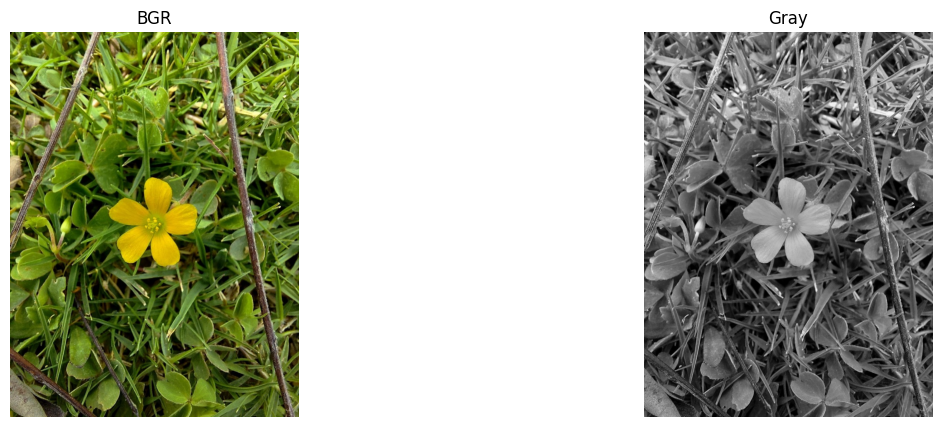

In [2]:
import numpy as np
import cv2 as cv
import matplotlib.pyplot as plt

img_name = 'garden.jpeg'
path = './images/'

def show(windows):
    plt.figure(figsize=(15, 5))
    count = len(windows)
    for i, (title, image) in enumerate(windows.items()):
        plt.subplot(1, count, i + 1)
        if len(image.shape) == 3: #3 y3ny el pic BGR
            img_disp = cv.cvtColor(image, cv.COLOR_BGR2RGB)
            plt.imshow(img_disp)
        else:
            plt.imshow(image, cmap='gray') #still gray





            cv  
        plt.title(title)
        plt.axis('off')
    plt.show()

img_bgr = cv.imread(path + img_name, cv.IMREAD_COLOR)       
img_gray = cv.imread(path + img_name, cv.IMREAD_GRAYSCALE)  
assert img_bgr is not None, "Cant read image"

print("BGR shape:", img_bgr.shape)
print("Gray shape:", img_gray.shape)

show({"BGR": img_bgr, "Gray": img_gray})

img_bgr = cv.resize(img_bgr, None, fx=0.5, fy=0.5)
img_gray = cv.resize(img_gray, None, fx=0.5, fy=0.5)

 Task 2 
Original: (512, 384, 3)
Down 60%: (307, 230, 3)
Up 200%: (1024, 768, 3)


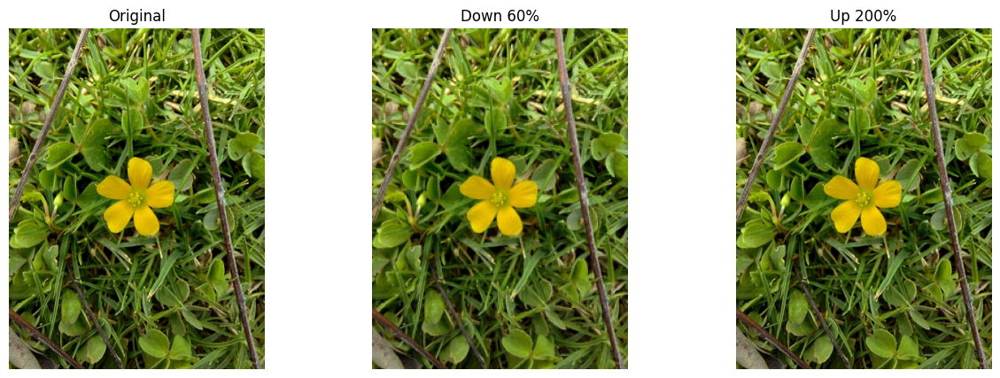

In [3]:
#TASK2
h, w, _ = img_bgr.shape

#  Downscale to 60% 
scale_percent = 60
new_h = int(scale_percent * h / 100)
new_w = int(scale_percent * w / 100)
dim = (new_w, new_h)   #w, h
down_img = cv.resize(img_bgr, dim, interpolation=cv.INTER_AREA)

#  Upscale to 200% 
scale_percent = 200
new_h = int(scale_percent * h / 100)
new_w = int(scale_percent * w / 100)
dim = (new_w, new_h)
up_img = cv.resize(img_bgr, dim, interpolation=cv.INTER_CUBIC) #CUBIC in up process better

print(" Task 2 ")
print("Original:", img_bgr.shape)
print("Down 60%:", down_img.shape)
print("Up 200%:", up_img.shape)

#Display instead of cv.imshow("original", img_bgr)
show({"Original": img_bgr, "Down 60%": down_img, "Up 200%": up_img})



Task 3
Only width=100 : (512, 100, 3)
Only height=200: (200, 384, 3)
Both 200x200   : (200, 100, 3)


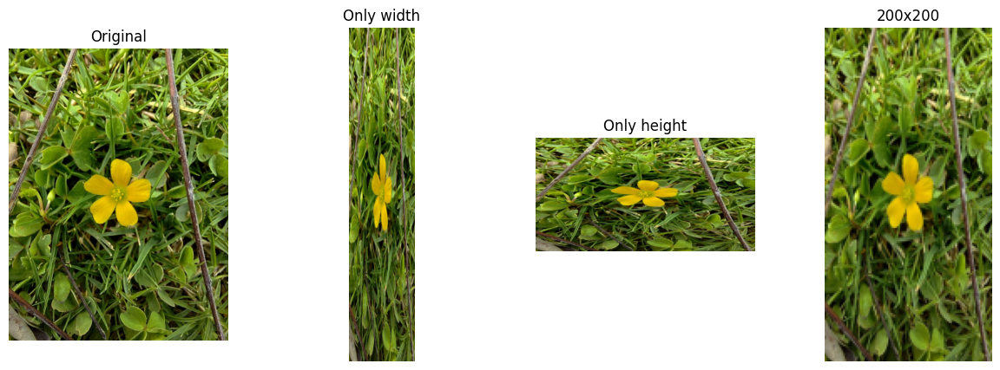

In [4]:
#TASK3
# width  
only_width = cv.resize(img_bgr, (100, h), interpolation=cv.INTER_AREA)
#height 
only_height = cv.resize(img_bgr, (w, 200), interpolation=cv.INTER_AREA)
# both (100, 200)
both = cv.resize(img_bgr, (100, 200), interpolation=cv.INTER_AREA)

print("Task 3")
print("Only width=100 :", only_width.shape)
print("Only height=200:", only_height.shape)
print("Both 200x200   :", both.shape)

show({"Original": img_bgr, "Only width": only_width,  "Only height": only_height, "200x200": both})

#resizing using factors x,y
up_linear = cv.resize(img_bgr, None, fx=1.2, fy=1.2, interpolation=cv.INTER_LINEAR)
up_nearest = cv.resize(img_bgr, None, fx=1.2, fy=1.2, interpolation=cv.INTER_NEAREST)
down_linear = cv.resize(img_bgr, None, fx=0.6, fy=0.6, interpolation=cv.INTER_LINEAR)
down_nearest = cv.resize(img_bgr, None, fx=0.6, fy=0.6, interpolation=cv.INTER_NEAREST)

 Task 4
Up   x1.2 : (614, 461, 3)
Down x0.6 : (307, 230, 3)


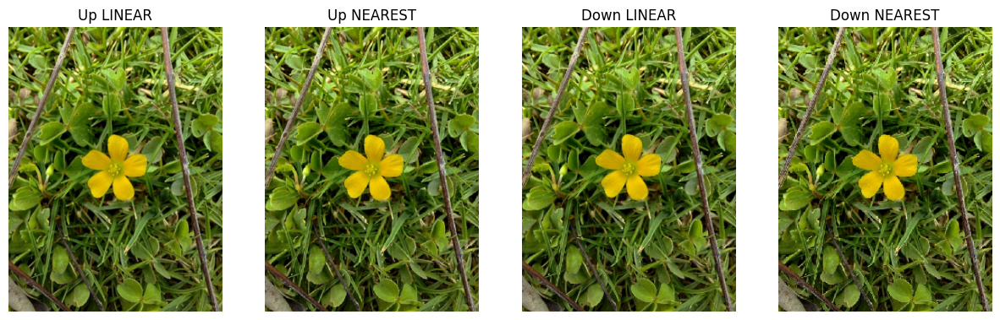

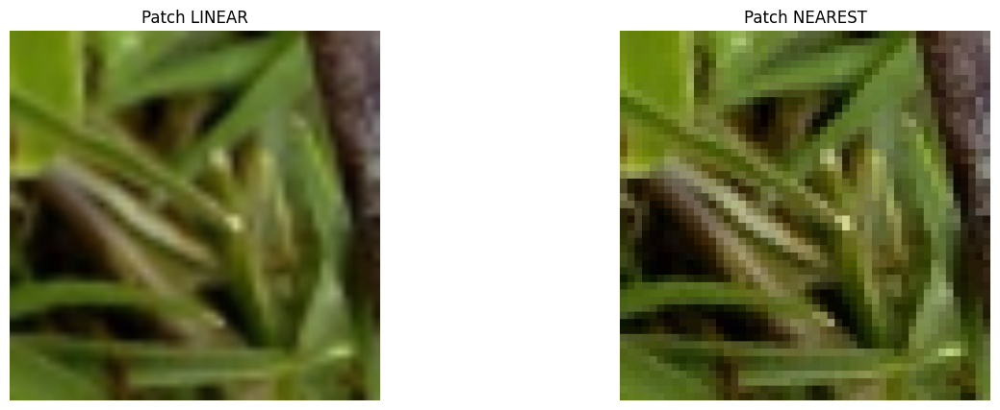

In [5]:
print(" Task 4")
print("Up   x1.2 :", up_linear.shape)
print("Down x0.6 :", down_linear.shape)

show({"Up LINEAR": up_linear, "Up NEAREST": up_nearest,
    "Down LINEAR": down_linear, "Down NEAREST": down_nearest})

# Zoom on a small patch (8x) to make the difference between the methods visible
patch = img_bgr[400:450, 300:350]   #b crop 50 x 50 pixel
patch_linear = cv.resize(patch, None, fx=8, fy=8, interpolation=cv.INTER_LINEAR)
patch_nearest = cv.resize(patch, None, fx=8, fy=8, interpolation=cv.INTER_NEAREST)
show({"Patch LINEAR": patch_linear, "Patch NEAREST": patch_nearest})


Task 5: Cropping an Image
Original shape: (512, 384, 3)
Cropped shape: (180, 150, 3)


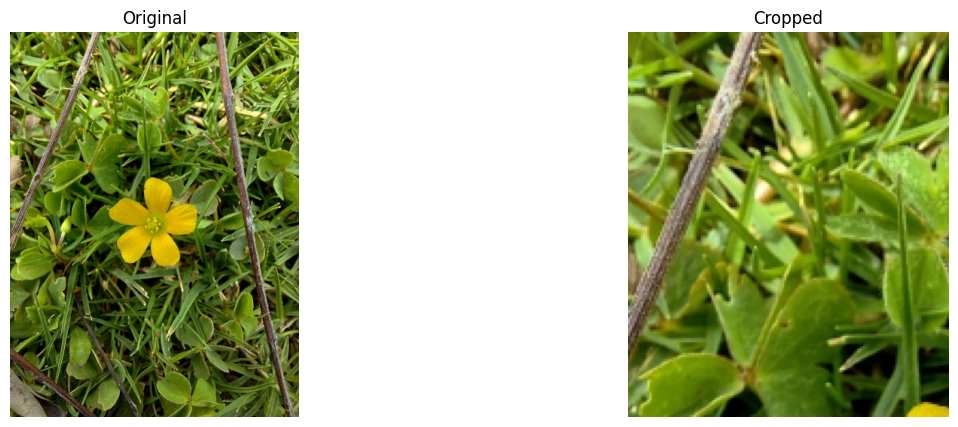

In [6]:
#TASK5
print("Task 5: Cropping an Image")
cropped_img = img_bgr[20:200, 50:200]
print("Original shape:", img_bgr.shape)
print("Cropped shape:", cropped_img.shape)
show({"Original": img_bgr, "Cropped": cropped_img})


# show({"Original": img_bgr})
#cv.waitKey(0)
#show({"Cropped": cropped_img_bgr})
#cv.waitKey(0)
#cv.destroyAllWindows() ليه الطريقة دي مش صح؟؟


Task 6: Splitting and Stitching
Block shape: (256, 192, 3)
Stitched equals original: True


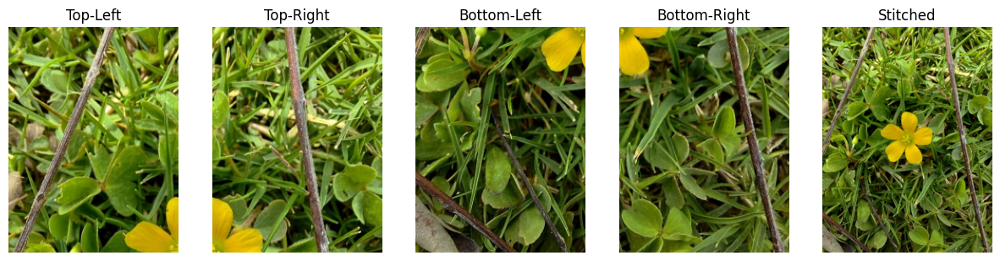

In [7]:
import numpy as np

print("Task 6: Splitting and Stitching")

h, w = img_bgr.shape[:2]
mid_h = h // 2
mid_w = w // 2

#slicing
top_left = img_bgr[:mid_h, :mid_w]
top_right = img_bgr[:mid_h, mid_w:]
bottom_left = img_bgr[mid_h:, :mid_w]
bottom_right = img_bgr[mid_h:, mid_w:]

top_half = np.hstack((top_left, top_right)) 
#np.hstack > horizontal stack stitching(tlz2) bel 3ard

bottom_half = np.hstack((bottom_left, bottom_right))
stitched = np.vstack((top_half, bottom_half))

print("Block shape:", top_left.shape)
print("Stitched equals original:", np.array_equal(img_bgr, stitched))

show({
    "Top-Left": top_left, 
    "Top-Right": top_right,
    "Bottom-Left": bottom_left, 
    "Bottom-Right": bottom_right,
    "Stitched": stitched
})

Task7
Rotated shapes: (512, 384, 3) (512, 384, 3) (512, 384, 3)


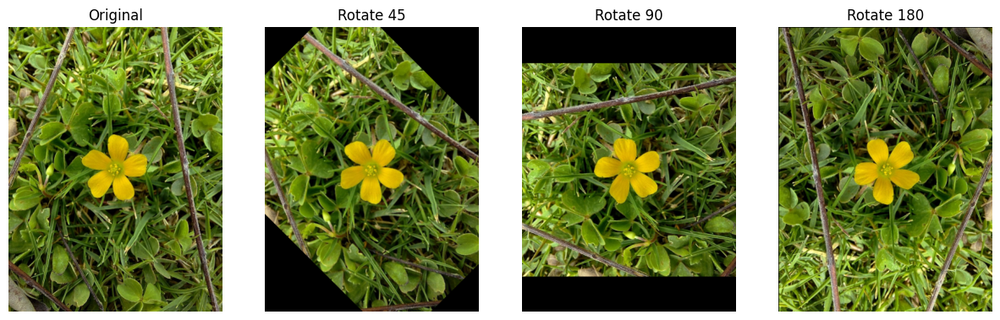

In [8]:
#TASK7

center = (w / 2, h / 2)   # center of rotation (x, y)

# positive angle = counter-clockwise
M45 = cv.getRotationMatrix2D(center, 45, 1)
M90 = cv.getRotationMatrix2D(center, 90, 1)
M180 = cv.getRotationMatrix2D(center, 180, 1)

# size is (width, height); keeping the same size cuts off the corners
rot45 = cv.warpAffine(img_bgr, M45, (w, h))
rot90 = cv.warpAffine(img_bgr, M90, (w, h))
rot180 = cv.warpAffine(img_bgr, M180, (w, h))

print("Task7")
print("Rotated shapes:", rot45.shape, rot90.shape, rot180.shape)

show({"Original": img_bgr, "Rotate 45": rot45,
    "Rotate 90": rot90, "Rotate 180": rot180})



Task8
One step : (512, 384, 3)
Two steps : (256, 192, 3)


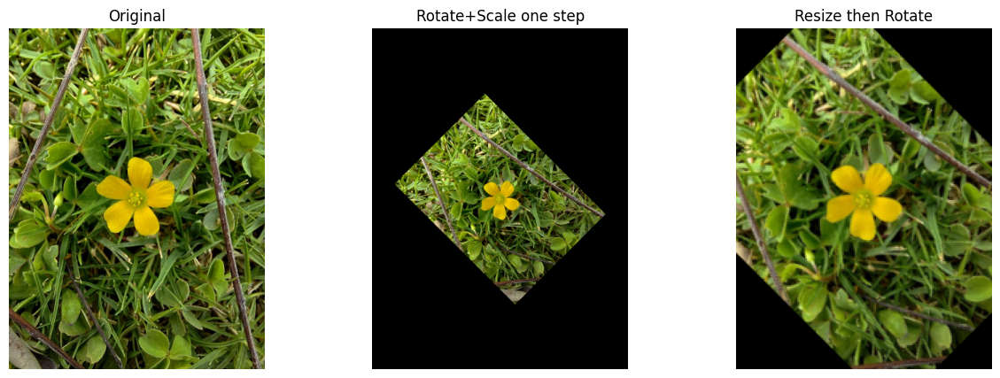

In [9]:
M_both = cv.getRotationMatrix2D(center, 45, 0.5)
one_step = cv.warpAffine(img_bgr, M_both, (w, h))

small = cv.resize(img_bgr, None, fx=0.5, fy=0.5, interpolation=cv.INTER_AREA)
sh, sw = small.shape[:2]
M_small = cv.getRotationMatrix2D((sw / 2, sh / 2), 45, 1)
two_steps = cv.warpAffine(small, M_small, (sw, sh))

print("Task8")
print("One step :", one_step.shape)
print("Two steps :", two_steps.shape)

show({"Original": img_bgr, "Rotate+Scale one step": one_step, "Resize then Rotate": two_steps})

Task 9: Color Spaces


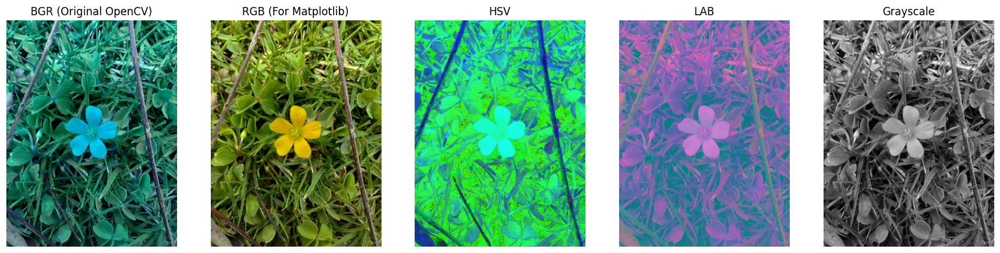

In [10]:
#Task9
import cv2 as cv
import matplotlib.pyplot as plt

print("Task 9: Color Spaces")

# 1. Read the image in default BGR format
img_bgr = cv.imread(path + img_name)

img_rgb = cv.cvtColor(img_bgr, cv.COLOR_BGR2RGB)

img_hsv = cv.cvtColor(img_bgr, cv.COLOR_BGR2HSV)

img_lab = cv.cvtColor(img_bgr, cv.COLOR_BGR2LAB)

img_gray = cv.cvtColor(img_bgr, cv.COLOR_BGR2GRAY)


# Setup the  size to display 5 images in a single row
plt.figure(figsize=(20, 8))

# BGR Image (Colors will look blueish because Matplotlib expects RGB)
plt.subplot(1, 5, 1)
plt.imshow(img_bgr)
plt.title("BGR (Original OpenCV)")
plt.axis('off')

# RGB Image (Normal colors)
plt.subplot(1, 5, 2)
plt.imshow(img_rgb)
plt.title("RGB (For Matplotlib)")
plt.axis('off')


plt.subplot(1, 5, 3)
plt.imshow(img_hsv)
plt.title("HSV")
plt.axis('off')


plt.subplot(1, 5, 4)
plt.imshow(img_lab)
plt.title("LAB")
plt.axis('off')

# Plot Grayscale Image
plt.subplot(1, 5, 5)
plt.imshow(img_gray, cmap='gray')
plt.title("Grayscale")
plt.axis('off')

plt.show()

Task 10: Image Sharpening


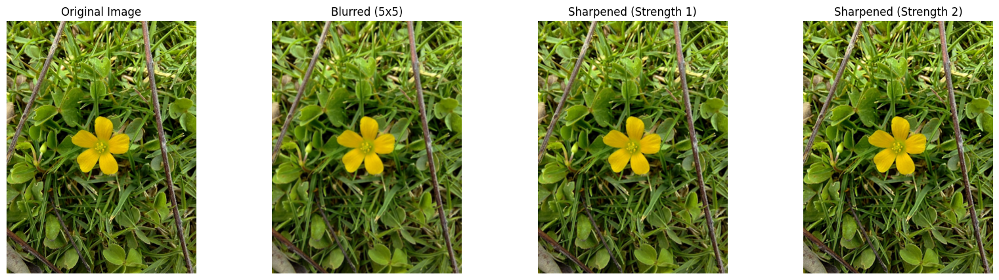

In [11]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

print("Task 10: Image Sharpening")

#  line da 34an colors ttl3 mzbota m4 blue
img_rgb = cv.cvtColor(img_bgr, cv.COLOR_BGR2RGB)

#  Apply blur
blurred_img = cv.blur(img_rgb, (5, 5)) #5x5 de karnel size

#  sharpening kernels
# Kernel 1: Standard strength
kernel_1 = np.array([[0, -1, 0], [-1, 5, -1], [0, -1, 0]])

# Kernel 2: Higher strength
kernel_2 = np.array([[0, -2, 0], [-2, 9, -2], [0, -2, 0]])

# 4. Apply sharpening kernels to BLURRED image
# -1 means output image have same depth as source image
sharpened_1 = cv.filter2D(blurred_img, -1, kernel_1)
sharpened_2 = cv.filter2D(blurred_img, -1, kernel_2)

# 5. Display the results for comparison
plt.figure(figsize=(20, 5))


plt.subplot(1, 4, 1)
plt.imshow(img_rgb)
plt.title("Original Image")
plt.axis('off')


plt.subplot(1, 4, 2)
plt.imshow(blurred_img)
plt.title("Blurred (5x5)")
plt.axis('off')


plt.subplot(1, 4, 3)
plt.imshow(sharpened_1)
plt.title("Sharpened (Strength 1)")
plt.axis('off')

plt.subplot(1, 4, 4)
plt.imshow(sharpened_2)
plt.title("Sharpened (Strength 2)")
plt.axis('off')

plt.show()

Task 11: Add Salt and Pepper Noise


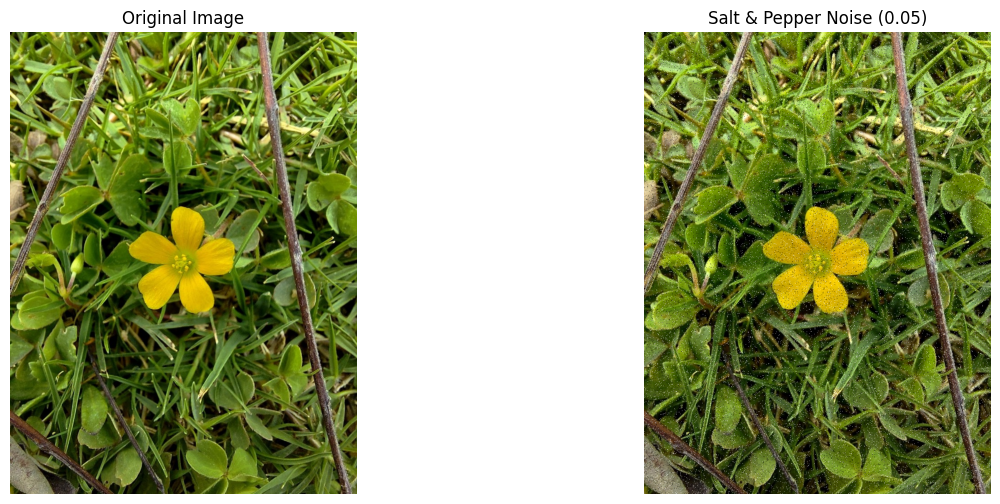

In [12]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

print("Task 11: Add Salt and Pepper Noise")

def add_salt_pepper_noise(image, density=0.05):

    noisy_img = image.copy()
    
    # 2. Get h and w 
    h, w = noisy_img.shape[:2]
    
    # 3. Generate  matrix of random numbers between 0 & 1
    rand_matrix = np.random.rand(h, w)
    
    # 4. Add Salt (White pixels = 255) 
    # Applied to pixels where the random number is less than half the density
    noisy_img[rand_matrix < (density / 2)] = 255
    
    # 5. Add Pepper (Black pixels = 0)
    # Applied to pixels where the random number is greater than 1 - (half the density)
    noisy_img[rand_matrix > 1 - (density / 2)] = 0
    
    return noisy_img

# Read the image and convert to RGB for Matplotlib
img_bgr = cv.imread(path + img_name)
img_rgb = cv.cvtColor(img_bgr, cv.COLOR_BGR2RGB)

# Apply the salt and pepper noise function
noisy_image = add_salt_pepper_noise(img_rgb, density=0.05)

# Display the results
plt.figure(figsize=(15, 6))

# Plot Original
plt.subplot(1, 2, 1)
plt.imshow(img_rgb)
plt.title("Original Image")
plt.axis('off')

# Plot Noisy
plt.subplot(1, 2, 2)
plt.imshow(noisy_image)
plt.title("Salt & Pepper Noise (0.05)")
plt.axis('off')

plt.show()

Task 13: Adaptive Median Filter


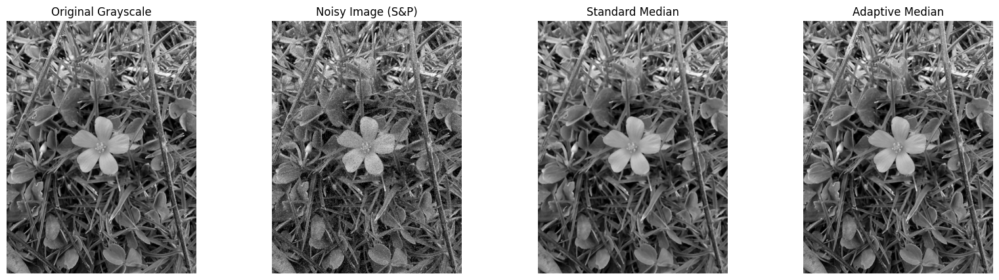

In [13]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

print("Task 13: Adaptive Median Filter")

def adaptive_median_filter(image, max_size=7):
    # Get image dimensions and create an empty output image
    h, w = image.shape
    output = np.zeros_like(image)
    
    # Pad the image edges so the window doesn't go out of bounds
    pad_size = max_size // 2
    padded_img = cv.copyMakeBorder(image, pad_size, pad_size, pad_size, pad_size, cv.BORDER_REFLECT)
    
    # Loop over every pixel in the image
    for y in range(h):
        for x in range(w):
            window_size = 3 # Start with a 3x3 window
            
            while window_size <= max_size:
                w_pad = window_size // 2
                
                # Extract the current window from the padded image
                py, px = y + pad_size, x + pad_size
                window = padded_img[py - w_pad : py + w_pad + 1, px - w_pad : px + w_pad + 1]
                
                # Calculate min, max, and median of the window
                z_min = np.min(window)
                z_max = np.max(window)
                z_med = np.median(window)
                z_xy = padded_img[py, px] # Current pixel value
                
                # Level A: Check if the median itself is noise
                if z_min < z_med < z_max:
                    # Level B: Check if the center pixel is noise
                    if z_min < z_xy < z_max:
                        output[y, x] = z_xy  # Not noise, keep original pixel
                    else:
                        output[y, x] = z_med # It is noise, replace with median
                    break # Done with this pixel, move to the next one
                else:
                    # The median is noise, increase window size and try again
                    window_size += 2
            
            # If we reached max_size and couldn't find a good median, just use the last median
            if window_size > max_size:
                output[y, x] = z_med
                
    return output

# 1. Read image and convert to grayscale (Filtering is usually applied to 2D grayscale)
img_bgr = cv.imread(path + img_name)
img_gray = cv.cvtColor(img_bgr, cv.COLOR_BGR2GRAY)

# 2. Generate Noisy Image (using Salt and Pepper logic)
noisy_gray = img_gray.copy()
rand_matrix = np.random.rand(*noisy_gray.shape)
density = 0.05
noisy_gray[rand_matrix < (density / 2)] = 255
noisy_gray[rand_matrix > 1 - (density / 2)] = 0

# 3. Apply standard median filter (OpenCV built-in, window size 5)
standard_median = cv.medianBlur(noisy_gray, 5)

# 4. Apply our custom adaptive median filter
adaptive_median = adaptive_median_filter(noisy_gray, max_size=7)

# 5. Display the results safely
plt.figure(figsize=(20, 5))

plt.subplot(1, 4, 1)
plt.imshow(img_gray, cmap='gray')
plt.title("Original Grayscale")
plt.axis('off')

plt.subplot(1, 4, 2)
plt.imshow(noisy_gray, cmap='gray')
plt.title("Noisy Image (S&P)")
plt.axis('off')

plt.subplot(1, 4, 3)
plt.imshow(standard_median, cmap='gray')
plt.title("Standard Median")
plt.axis('off')

plt.subplot(1, 4, 4)
plt.imshow(adaptive_median, cmap='gray')
plt.title("Adaptive Median")
plt.axis('off')

plt.show()

Task 14: Bilateral Filter
Applying custom filter... (This might take a minute, please wait)


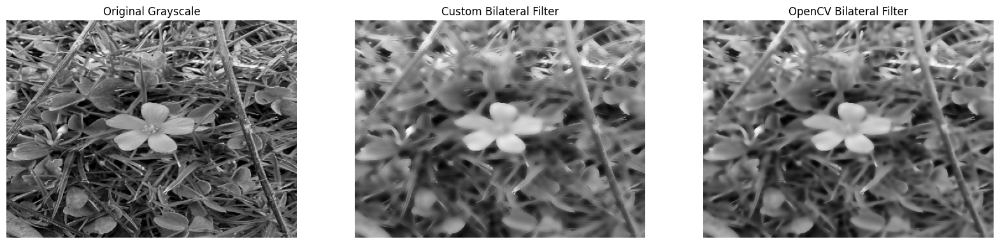

In [14]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

print("Task 14: Bilateral Filter")

def custom_bilateral_filter(image, diameter, sigma_color, sigma_space):
    # 1. Get image dimensions and prepare output
    h, w = image.shape
    output = np.zeros_like(image, dtype=np.float32)
    
    # 2. Calculate the radius (half of the diameter) and pad the image
    radius = diameter // 2
    padded_img = cv.copyMakeBorder(image, radius, radius, radius, radius, cv.BORDER_REFLECT).astype(np.float32)
    
    # 3. Pre-calculate the spatial Gaussian weights (distance from center)
    # This stays the same for every pixel window
    y_grid, x_grid = np.ogrid[-radius:radius+1, -radius:radius+1]
    spatial_weights = np.exp(-(x_grid**2 + y_grid**2) / (2.0 * sigma_space**2))
    
    # 4. Loop through every pixel in the original image
    print("Applying custom filter... (This might take a minute, please wait)")
    for y in range(h):
        for x in range(w):
            # Extract the current neighborhood window
            window = padded_img[y : y + diameter, x : x + diameter]
            
            # Get the intensity value of the center pixel
            center_pixel = padded_img[y + radius, x + radius]
            
            # Calculate the color Gaussian weights (difference in intensity)
            color_diffs = window - center_pixel
            color_weights = np.exp(-(color_diffs**2) / (2.0 * sigma_color**2))
            
            # Multiply spatial weights by color weights
            total_weights = spatial_weights * color_weights
            
            # Compute the weighted average for the center pixel
            output[y, x] = np.sum(window * total_weights) / np.sum(total_weights)
            
    # 5. Return the final image converted back to standard 8-bit format
    return np.clip(output, 0, 255).astype(np.uint8)

# Read the image and convert to Grayscale 
# (Applying custom Python loops on 3 color channels is very slow, grayscale is faster for testing)
img_bgr = cv.imread(path + img_name)
img_gray = cv.cvtColor(img_bgr, cv.COLOR_BGR2GRAY)

# Resize the image slightly to make the custom loop run faster for the assignment
img_small = cv.resize(img_gray, (400, 300))

# Define filter parameters
diameter = 9
sigma_color = 75.0
sigma_space = 75.0

# Apply the Custom Bilateral Filter
custom_filtered = custom_bilateral_filter(img_small, diameter, sigma_color, sigma_space)

# Apply OpenCV's built-in Bilateral Filter for comparison
opencv_filtered = cv.bilateralFilter(img_small, diameter, sigma_color, sigma_space)

# Display the results
plt.figure(figsize=(20, 5))

plt.subplot(1, 3, 1)
plt.imshow(img_small, cmap='gray')
plt.title("Original Grayscale")
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(custom_filtered, cmap='gray')
plt.title("Custom Bilateral Filter")
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(opencv_filtered, cmap='gray')
plt.title("OpenCV Bilateral Filter")
plt.axis('off')

plt.show()

In [15]:
#import cv2 as cv
import numpy as np
import time

print("Task 17: Performance Comparison")

# 1. Read the image and make it "large" (e.g., 800x600)
img_bgr = cv.imread(path + img_name)
img_gray = cv.cvtColor(img_bgr, cv.COLOR_BGR2GRAY)
large_img = cv.resize(img_gray, (800, 600))

# 2. Add Salt and Pepper noise to the large image
noisy_large = large_img.copy()
density = 0.05
rand_matrix = np.random.rand(*noisy_large.shape)
noisy_large[rand_matrix < (density / 2)] = 255
noisy_large[rand_matrix > 1 - (density / 2)] = 0

# 3. Time the Standard Median Filter
print("Running Standard Median Filter...")
start_time = time.time()
standard_result = cv.medianBlur(noisy_large, 5)
end_time = time.time()
standard_time = end_time - start_time
print(f"Standard Median Filter took: {standard_time:.4f} seconds")

# 4. Time the Custom Adaptive Median Filter (From Task 13)
# Make sure you ran the Task 13 cell first so Python remembers the function!
print("Running Adaptive Median Filter... (Please wait, this will take longer)")
start_time = time.time()
adaptive_result = adaptive_median_filter(noisy_large, max_size=7)
end_time = time.time()
adaptive_time = end_time - start_time
print(f"Adaptive Median Filter took: {adaptive_time:.4f} seconds")


# 5. Discussion Output
discussion = ""

print(discussion)

Task 17: Performance Comparison
Running Standard Median Filter...
Standard Median Filter took: 0.0010 seconds
Running Adaptive Median Filter... (Please wait, this will take longer)
Adaptive Median Filter took: 43.7773 seconds



In [16]:
#2ndtask2
# DoG: It highlights the edges and lines in the image, 
# usually in black and gray or white.
#LoG:It detects edges and changes in brightness,
#  usually in grayscale image.
#Bilateral Filter: It keeps the original colors and makes
#  the image smoother with keeping important edges
#  and details.


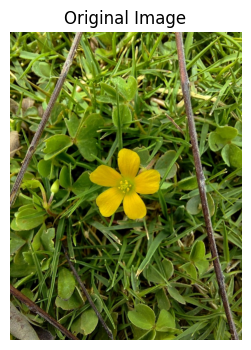

In [17]:


import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

img_name = 'garden.jpeg'
path = './images/'

img = cv.imread( './images/' + 'garden.jpeg')

if img is None:
    print("Image not found. Check the image path.")
else:
    img_rgb = cv.cvtColor(img, cv.COLOR_BGR2RGB)

    plt.figure(figsize=(6, 4))
    plt.imshow(img_rgb)
    plt.title("Original Image")
    plt.axis("off")
    plt.show()

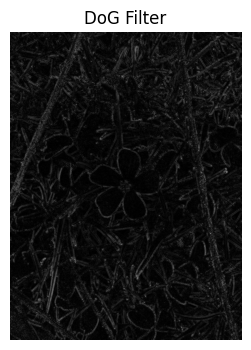

In [18]:

gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

blur1 = cv.GaussianBlur(gray, (5, 5), 1)
blur2 = cv.GaussianBlur(gray, (5, 5), 3)

# Calculate Difference of Gaussians
dog = cv.absdiff(blur1, blur2)

plt.figure(figsize=(6, 4))
plt.imshow(dog, cmap="gray")
plt.title("DoG Filter")
plt.axis("off")
plt.show()

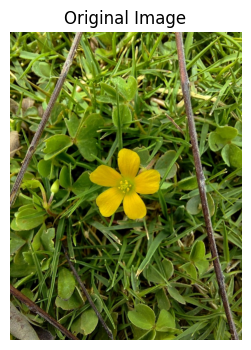

In [19]:


import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

img_name = 'garden.jpeg'
path = './images/'

img = cv.imread( './images/' + 'garden.jpeg' )

if img is None:
    print("Image not found. Check the image path.")
else:
    img_rgb = cv.cvtColor(img, cv.COLOR_BGR2RGB)
    plt.figure(figsize=(6, 4))
    plt.imshow(img_rgb)
    plt.title("Original Image")
    plt.axis("off")
    plt.show()

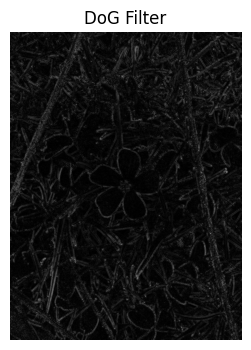

In [20]:

# Convert the image to grayscale
gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

# Apply two Gaussian filters
blur1 = cv.GaussianBlur(gray, (5, 5), 1)
blur2 = cv.GaussianBlur(gray, (5, 5), 3)

# Calculate Difference of Gaussians
dog = cv.absdiff(blur1, blur2)

plt.figure(figsize=(6, 4))
plt.imshow(dog, cmap="gray")
plt.title("DoG Filter")
plt.axis("off")
plt.show()

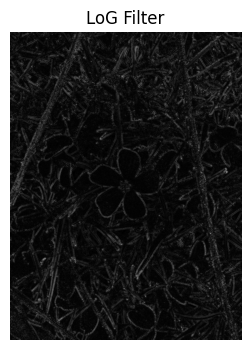

In [21]:

# Apply Gaussian Blur
blur = cv.GaussianBlur(gray, (5, 5), 1)

# Apply Laplacian
log = cv.Laplacian(blur, cv.CV_64F)

# Convert the result for display
log_display = cv.convertScaleAbs(log)


plt.figure(figsize=(6, 4))
plt.imshow(log_display, cmap="gray")
plt.title("LoG Filter")
plt.axis("off")
plt.show()

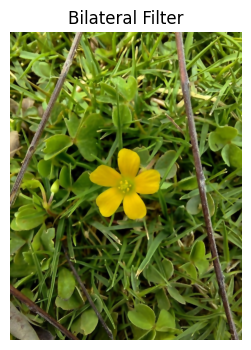

In [22]:

# Apply Bilateral Filter
bilateral = cv.bilateralFilter(
    img,
    d=9,
    sigmaColor=75,
    sigmaSpace=75
)

# Convert BGR to RGB
bilateral_rgb = cv.cvtColor(bilateral, cv.COLOR_BGR2RGB)


plt.figure(figsize=(6, 4))
plt.imshow(bilateral_rgb)
plt.title("Bilateral Filter")
plt.axis("off")
plt.show()

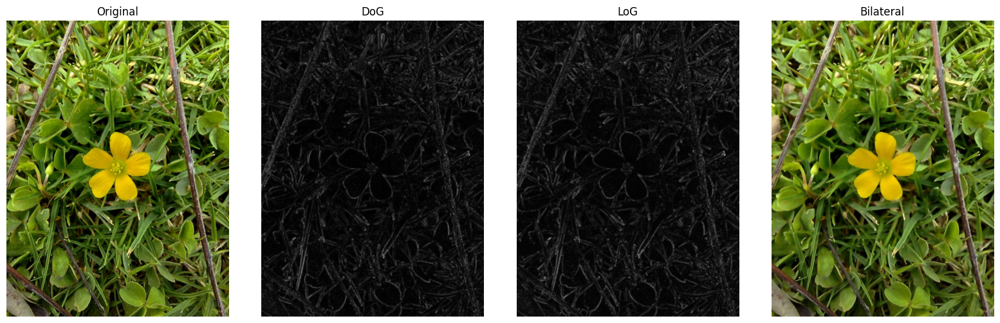

In [23]:

plt.figure(figsize=(16, 5))

plt.subplot(1, 4, 1)
plt.imshow(img_rgb)
plt.title("Original")
plt.axis("off")

plt.subplot(1, 4, 2)
plt.imshow(dog, cmap="gray")
plt.title("DoG")
plt.axis("off")

plt.subplot(1, 4, 3)
plt.imshow(log_display, cmap="gray")
plt.title("LoG")
plt.axis("off")

plt.subplot(1, 4, 4)
plt.imshow(bilateral_rgb)
plt.title("Bilateral")
plt.axis("off")

plt.tight_layout()
plt.show()

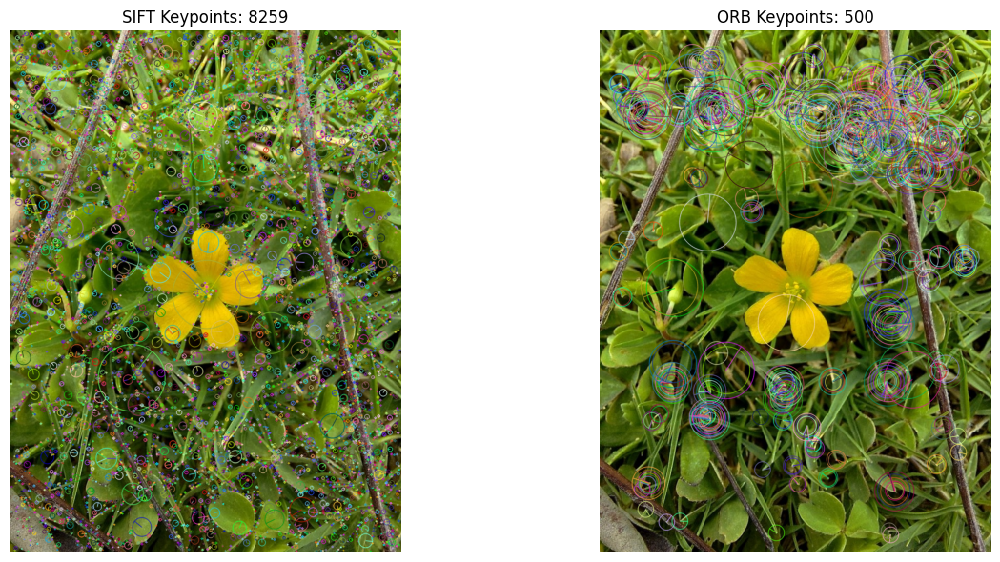

Number of SIFT keypoints: 8259
Number of ORB keypoints: 500


In [24]:
img = cv.imread('./images/garden.jpeg')

if img is None:
    print("Image not found. Check the image path.")
else:
    # Convert image to grayscale
    gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

    # Create SIFT and ORB detectors
    sift = cv.SIFT_create()
    orb = cv.ORB_create()

    # Detect keypoints and descriptors
    kp_sift, des_sift = sift.detectAndCompute(gray, None)
    kp_orb, des_orb = orb.detectAndCompute(gray, None)

    # Draw keypoints on the image
    img_sift = cv.drawKeypoints(
        img, kp_sift, None,
        flags=cv.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS
    )

    img_orb = cv.drawKeypoints(
        img, kp_orb, None,
        flags=cv.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS
    )


    plt.figure(figsize=(14, 6))

    plt.subplot(1, 2, 1)
    plt.imshow(cv.cvtColor(img_sift, cv.COLOR_BGR2RGB))
    plt.title(f'SIFT Keypoints: {len(kp_sift)}')
    plt.axis('off')

    plt.subplot(1, 2, 2)
    plt.imshow(cv.cvtColor(img_orb, cv.COLOR_BGR2RGB))
    plt.title(f'ORB Keypoints: {len(kp_orb)}')
    plt.axis('off')

    plt.tight_layout()
    plt.show()

    print("Number of SIFT keypoints:", len(kp_sift))
    print("Number of ORB keypoints:", len(kp_orb))

In [25]:
# How do the number and distribution of keypoints differ between SIFT and ORB?

#SIFT detected 8259 keypoints, while ORB detected 500 keypoints
#  SIFT detected  more keypoints and captured more details
#  ORB detected fewer keypoints, which were limited to 500 
#  Both methods detect keypoints around important features, but their distribution may differ
# depending on the image details.


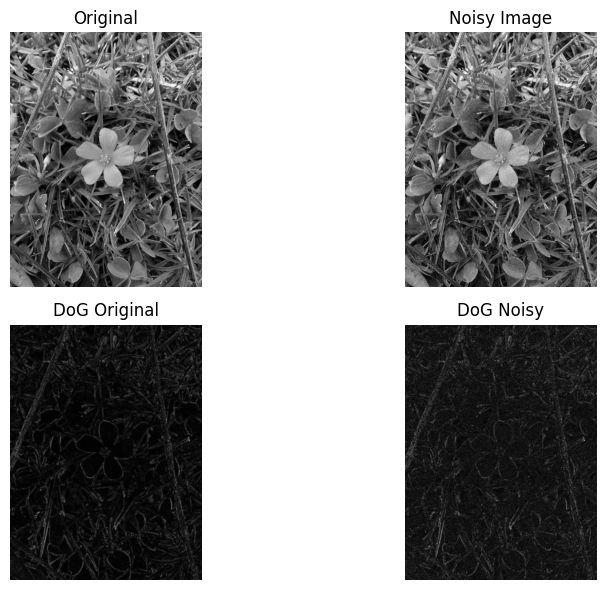

In [26]:
#task3/ass_2

img = cv.imread('images/garden.jpeg', 0)

#zodt noise
noise = np.random.normal(0, 20, img.shape)
noisy = np.clip(img + noise, 0, 255).astype('uint8')

# Apply DoG to the original image
blur1 = cv.GaussianBlur(img, (5, 5), 1)
blur2 = cv.GaussianBlur(img, (5, 5), 3)
dog1 = cv.absdiff(blur1, blur2)

# Apply DoG to the noisy image
blur3 = cv.GaussianBlur(noisy, (5, 5), 1)
blur4 = cv.GaussianBlur(noisy, (5, 5), 3)
dog2 = cv.absdiff(blur3, blur4)

plt.figure(figsize=(10, 6))

plt.subplot(2, 2, 1)
plt.imshow(img, cmap='gray')
plt.title('Original')
plt.axis('off')

plt.subplot(2, 2, 2)
plt.imshow(noisy, cmap='gray')
plt.title('Noisy Image')
plt.axis('off')

plt.subplot(2, 2, 3)
plt.imshow(dog1, cmap='gray')
plt.title('DoG Original')
plt.axis('off')

plt.subplot(2, 2, 4)
plt.imshow(dog2, cmap='gray')
plt.title('DoG Noisy')
plt.axis('off')

plt.tight_layout()
plt.show()


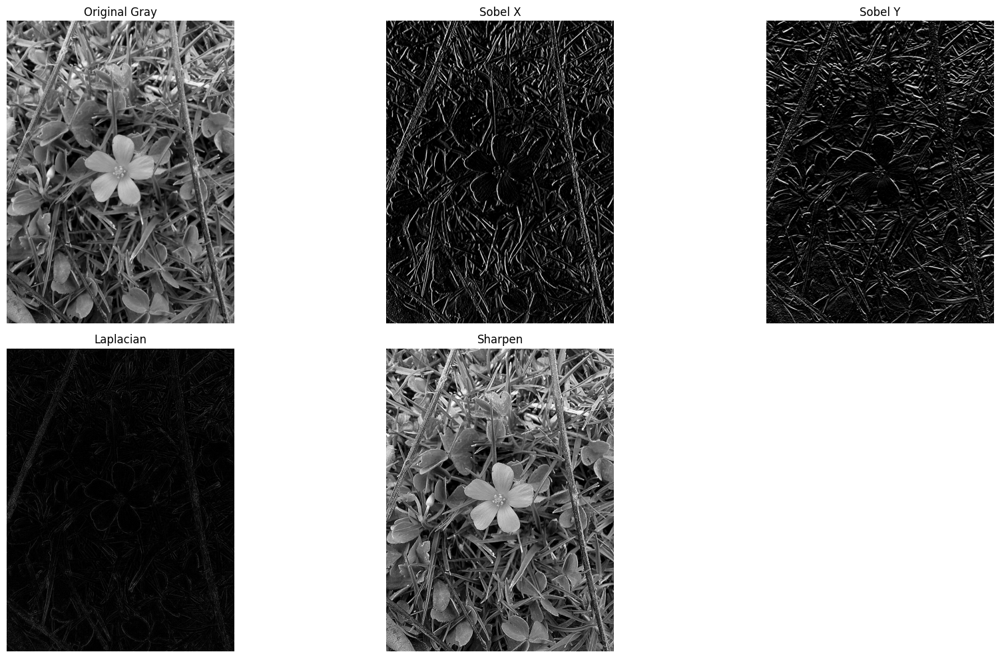

In [27]:
#task3.1
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt


img = cv.imread('/Users/tasnemtamer/Downloads/sky/images/garden.jpeg') 
img_rgb = cv.cvtColor(img, cv.COLOR_BGR2RGB)
gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

sobel_x = np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]])
sobel_y = np.array([[-1, -2, -1], [0, 0, 0], [1, 2, 1]])
laplacian = np.array([[0, 1, 0], [1, -4, 1], [0, 1, 0]])
sharpen = np.array([[0, -1, 0], [-1, 5, -1], [0, -1, 0]])

filtered_sobel_x = cv.filter2D(gray, -1, sobel_x)
filtered_sobel_y = cv.filter2D(gray, -1, sobel_y)
filtered_laplacian = cv.filter2D(gray, -1, laplacian)
filtered_sharpen = cv.filter2D(gray, -1, sharpen)

titles = ['Original Gray', 'Sobel X', 'Sobel Y', 'Laplacian', 'Sharpen']
images = [gray, filtered_sobel_x, filtered_sobel_y, filtered_laplacian, filtered_sharpen]

plt.figure(figsize=(18, 10))
for i in range(5):
    plt.subplot(2, 3, i+1)
    plt.imshow(images[i], cmap='gray')
    plt.title(titles[i])
    plt.axis('off')
    
plt.tight_layout()
plt.show()
